
# 📊 EDA de un portafolio de activos con Python
### Matplotlib · Seaborn · Pandas · yfinance

**Curso:** Lenguajes de programación  
**Tema:** Visualización y Análisis Exploratorio de Datos (EDA)  
**Caso:** análisis exploratorio de un portafolio de activos financieros

---

## 🎯 ¿Qué vamos a aprender?

Al terminar este notebook podrás:

- reconocer qué es una librería y para qué sirve;
- diferenciar **dato, variable, gráfico e interpretación**;
- crear gráficos básicos con **Matplotlib**;
- utilizar **Seaborn** para explorar distribuciones y relaciones;
- interpretar correctamente los gráficos;
- descargar datos históricos con **yfinance**;
- calcular rendimientos;
- explorar volatilidad, distribución y correlación;
- construir una primera lectura exploratoria de un portafolio.

> **Idea central:** un gráfico no es el resultado del análisis.  
> El gráfico es una herramienta que nos ayuda a **formular preguntas, encontrar patrones y comunicar hallazgos**.



## 🧭 Ruta de la clase

Trabajaremos de manera incremental:

**1. Datos → 2. Variables → 3. Gráfico → 4. Interpretación → 5. EDA → 6. Datos financieros reales**

| Etapa | Pregunta |
|---|---|
| Conceptos | ¿Qué estamos visualizando? |
| Matplotlib | ¿Cómo se construye un gráfico? |
| Seaborn | ¿Cómo exploramos una variable o relación? |
| EDA | ¿Qué patrones encontramos? |
| yfinance | ¿Cómo trabajamos con datos reales? |
| Portafolio | ¿Cómo se comportan conjuntamente los activos? |



# 1. Antes de graficar: pensemos como analistas

Supongamos que tenemos:

| Día | Precio |
|---:|---:|
| 1 | 100 |
| 2 | 103 |
| 3 | 101 |
| 4 | 108 |
| 5 | 112 |

Tenemos dos conceptos diferentes:

### Variable
Una característica que podemos observar o medir.  
Ejemplo: `Precio`.

### Observación
Un valor concreto de una variable.  
Ejemplo: el precio del día 4 es `108`.

### ¿Por qué graficar?

La tabla nos da los valores. El gráfico nos permite **ver la estructura de los datos**.

Por ejemplo:

- ¿el precio está aumentando?
- ¿hay caídas?
- ¿hay cambios bruscos?
- ¿existe una tendencia?

Ese proceso de preguntar, observar y encontrar patrones forma parte del **Análisis Exploratorio de Datos (EDA)**.



# 2. Las librerías que vamos a utilizar

Una **librería** es un conjunto de código reutilizable que otras personas han desarrollado para resolver problemas.

Hoy utilizaremos:

### 🐼 Pandas
Para trabajar con datos tabulares.

### 📈 Matplotlib
Para construir y personalizar visualizaciones.

### 🎨 Seaborn
Para crear visualizaciones estadísticas de forma sencilla y trabajar cómodamente con DataFrames.

### 💰 yfinance
Para obtener datos históricos de activos financieros desde Yahoo Finance.

La relación será:

```text
yfinance
   ↓
datos financieros
   ↓
Pandas
   ↓
transformaciones
   ↓
Matplotlib / Seaborn
   ↓
visualización
   ↓
interpretación
```


In [19]:
# Importamos las librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual básica
sns.set_theme(style="whitegrid")

# Para que los gráficos aparezcan dentro del notebook
%matplotlib inline



## ¿Qué significa `import`?

Cuando escribimos:

```python
import matplotlib.pyplot as plt
```

estamos diciendo:

> "Quiero utilizar el módulo `pyplot` de la librería `matplotlib` y voy a llamarlo `plt`."

Por eso posteriormente podemos escribir:

```python
plt.plot(...)
```

El nombre `plt` es un **alias**. No es obligatorio llamarlo así, pero es una convención muy utilizada.

Lo mismo ocurre con:

```python
import seaborn as sns
import pandas as pd
import numpy as np
```



# 3. Nuestro primer gráfico: de una tabla a una visualización

Comencemos con datos muy pequeños para entender **qué hace cada instrucción**.

Tenemos el precio de un activo durante cinco días.


In [2]:
dias = [1, 2, 3, 4, 5]
precios = [100, 103, 101, 108, 112]

datos_ejemplo = pd.DataFrame({
    "Día": dias,
    "Precio": precios
})

datos_ejemplo


,Día,Precio
0,1,100
1,2,103
2,3,101
3,4,108
4,5,112



### Primer intento

Queremos representar:

- eje X → día
- eje Y → precio

La función `plot()` recibe normalmente una serie de valores para X y otra para Y.


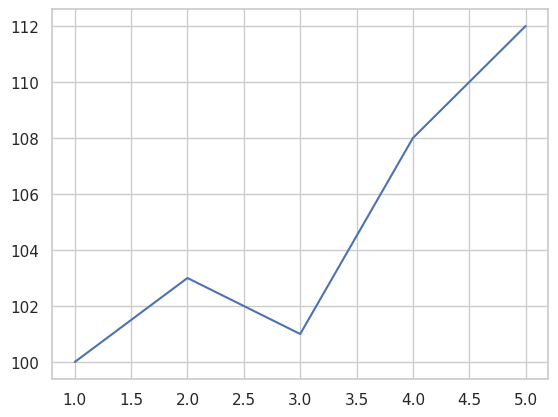

In [3]:
plt.plot(dias, precios)
plt.show()



## 🔎 ¿Qué acaba de ocurrir?

`plt.plot(x, y)`:

- toma los valores de `x`;
- toma los valores de `y`;
- coloca cada par `(x, y)` en el plano;
- conecta los puntos.

En nuestro ejemplo:

```text
(1,100)
(2,103)
(3,101)
(4,108)
(5,112)
```

### ¿Cómo lo interpretamos?

No debemos decir simplemente "el gráfico sube".

Podemos decir:

> **El precio presenta una tendencia general creciente durante el período observado, aunque existe una disminución entre los días 2 y 3.**

Esa segunda frase ya es una **interpretación**.



# 4. Hacer que el gráfico comunique mejor

Un gráfico debe permitir que otra persona entienda rápidamente:

1. **qué está viendo**;
2. **qué representan los ejes**;
3. **qué unidad se está utilizando**;
4. **qué período se está observando**.

Para eso agregamos título y etiquetas.


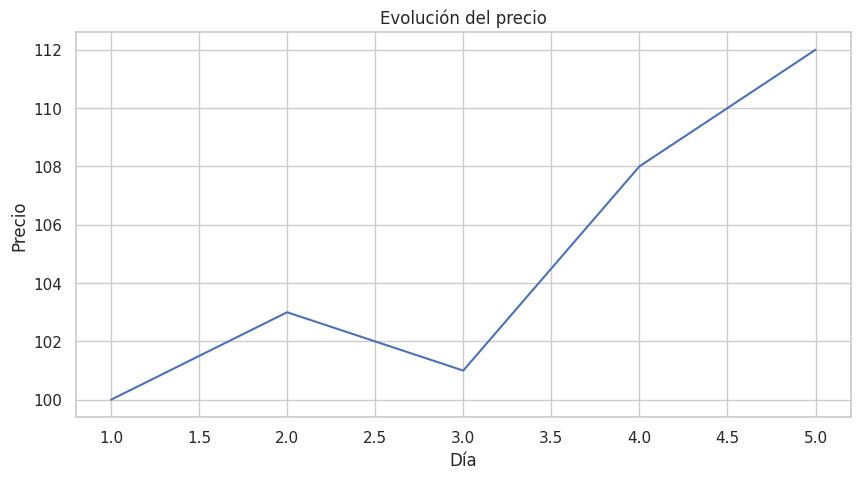

In [4]:
plt.figure(figsize=(10, 5))

plt.plot(dias, precios)

plt.title("Evolución del precio")
plt.xlabel("Día")
plt.ylabel("Precio")

plt.show()



## 🧩 Anatomía de un gráfico

```text
                 TÍTULO
        Evolución del precio

  Y
  ↑
  │             ●
  │          ●
  │     ●
  │        ●
  │  ●
  └──────────────────────→ X
       Día
```

### Elementos principales

- **Título:** comunica qué estamos observando.
- **Eje X:** normalmente representa tiempo o una variable explicativa.
- **Eje Y:** representa la variable que queremos analizar.
- **Línea/puntos:** representan los datos.
- **Leyenda:** identifica las series cuando tenemos varias.



# 5. La interfaz orientada a objetos de Matplotlib

Hasta ahora utilizamos `plt` directamente.

Existe otra forma muy importante:

```python
fig, ax = plt.subplots()
```

Aquí aparecen dos objetos:

### `fig`
Es la **figura completa**, el espacio donde estará nuestro gráfico.

### `ax`
Es el **área de ejes** donde realmente dibujamos.

Una forma sencilla de imaginarlo:

```text
Figure
┌─────────────────────────────┐
│                             │
│       Axes                  │
│     ┌───────────────┐       │
│     │   gráfico     │       │
│     │               │       │
│     └───────────────┘       │
│                             │
└─────────────────────────────┘
```


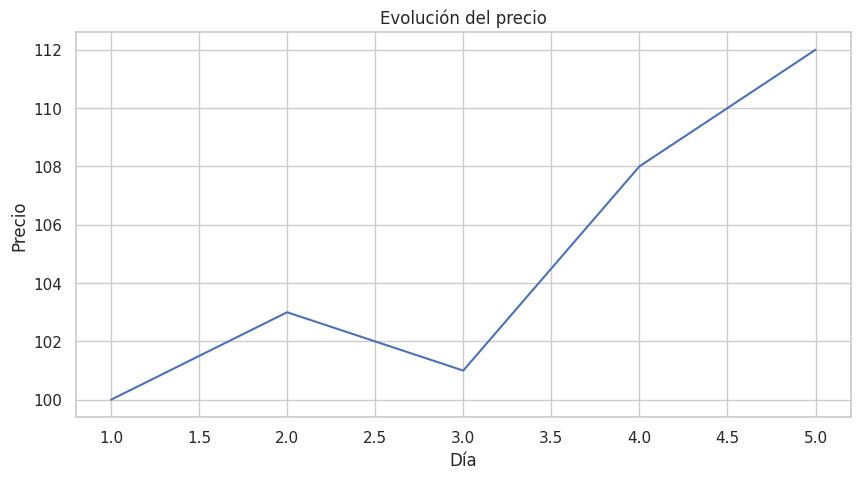

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(dias, precios)

ax.set_title("Evolución del precio")
ax.set_xlabel("Día")
ax.set_ylabel("Precio")

plt.show()



### ¿Por qué aprender esta forma?

Cuando los gráficos se vuelven más complejos, trabajar con `fig` y `ax` nos da mayor control.

Por ejemplo, podemos tener varios gráficos dentro de una misma figura y controlar cada eje por separado.

**Regla práctica para la clase:**

- `plt.plot()` → muy útil para comenzar.
- `fig, ax = plt.subplots()` → recomendable cuando queremos construir gráficos de forma más estructurada.



# 6. Gráficos de varias series

Ahora supongamos que tenemos tres activos.


In [6]:
precios_portafolio = pd.DataFrame({
    "AAPL": [100, 103, 101, 108, 112],
    "MSFT": [100, 102, 104, 106, 109],
    "NVDA": [100, 98, 105, 110, 120]
}, index=[1, 2, 3, 4, 5])

precios_portafolio


,AAPL,MSFT,NVDA
1,100,100,100
2,103,102,98
3,101,104,105
4,108,106,110
5,112,109,120



Si graficamos los precios directamente, podemos comparar las series.

Pero aparece un problema importante:

> ¿Cómo comparamos activos que originalmente tienen precios diferentes?

Por ahora nuestros datos comienzan todos en 100. Esto es intencional: queremos concentrarnos en la **forma de la serie** antes de introducir los rendimientos.


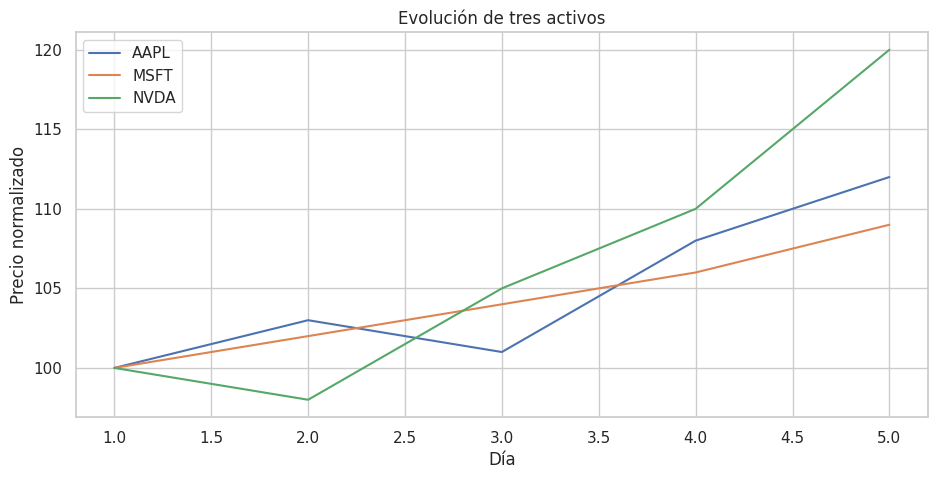

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(precios_portafolio.index, precios_portafolio["AAPL"], label="AAPL")
ax.plot(precios_portafolio.index, precios_portafolio["MSFT"], label="MSFT")
ax.plot(precios_portafolio.index, precios_portafolio["NVDA"], label="NVDA")

ax.set_title("Evolución de tres activos")
ax.set_xlabel("Día")
ax.set_ylabel("Precio normalizado")
ax.legend()

plt.show()



## 🧠 Interpretación

Observe primero, **después interprete**.

Preguntas:

1. ¿Cuál serie termina más arriba?
2. ¿Cuál presenta más cambios?
3. ¿Hay momentos en los que dos activos se mueven en direcciones diferentes?
4. ¿Podemos concluir cuál es "mejor" solamente con este gráfico?

La última pregunta es importante:

> **No.** Un gráfico puede mostrar comportamiento histórico, pero no convierte automáticamente ese comportamiento en una recomendación de inversión.



# 7. Seaborn: visualización orientada al análisis estadístico

Seaborn está construido sobre Matplotlib y facilita muchos gráficos estadísticos.

Una ventaja importante es que puede trabajar directamente con estructuras de Pandas.

Vamos a utilizar primero un **histograma**.


In [8]:
# Generamos una muestra sencilla de rendimientos

np.random.seed(42)

rendimientos_ejemplo = np.random.normal(
    loc=0.001,
    scale=0.02,
    size=500
)

rendimientos_ejemplo[:10]


array([ 0.01093428, -0.00176529,  0.01395377,  0.0314606 , -0.00368307,
       -0.00368274,  0.03258426,  0.01634869, -0.00838949,  0.0118512 ])


## ¿Qué pregunta responde un histograma?

Un histograma permite observar cómo se distribuyen los valores.

Por ejemplo:

> ¿En qué rango se concentran los rendimientos?


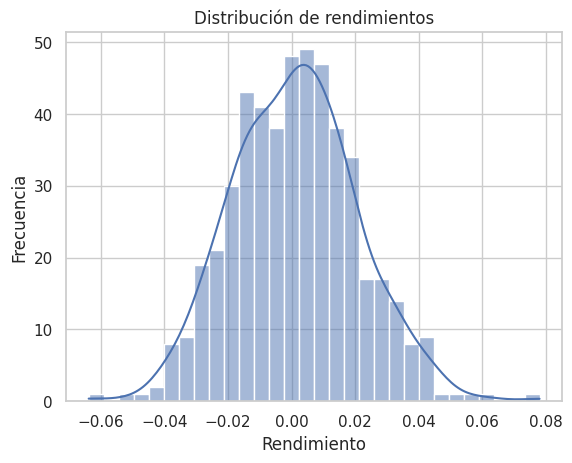

In [9]:
sns.histplot(
    rendimientos_ejemplo,
    bins=30,
    kde=True
)

plt.title("Distribución de rendimientos")
plt.xlabel("Rendimiento")
plt.ylabel("Frecuencia")

plt.show()



## 🔎 ¿Cómo interpretar un histograma?

Observemos:

### Centro
¿Dónde se concentran la mayoría de los valores?

### Dispersión
¿Qué tan extendidos están los datos?

### Colas
¿Hay valores alejados del centro?

### Forma
¿La distribución parece simétrica o presenta algún sesgo?

**Importante:** la forma del histograma depende de decisiones como el número de `bins`. No debemos interpretar cada detalle visual como una propiedad exacta de los datos.



# 8. Boxplot: detectar dispersión y valores extremos

Un boxplot resume visualmente una distribución.

Conceptualmente muestra:

- mediana;
- cuartiles;
- rango intercuartílico;
- posibles valores extremos.



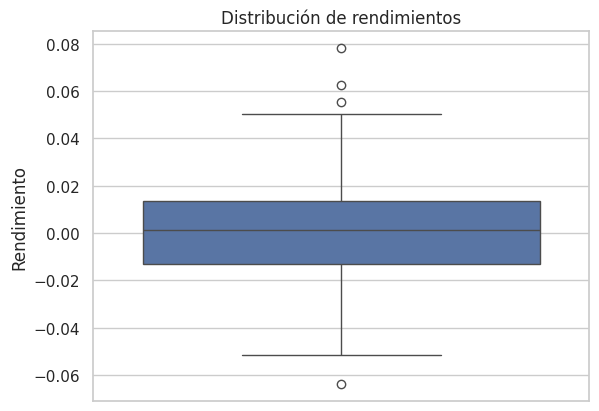

In [10]:
sns.boxplot(y=rendimientos_ejemplo)

plt.title("Distribución de rendimientos")
plt.ylabel("Rendimiento")

plt.show()



### Preguntas para interpretar

- ¿Dónde está la mediana?
- ¿Qué tan grande es la caja?
- ¿Qué tan largos son los bigotes?
- ¿Aparecen observaciones alejadas?

El objetivo no es memorizar la forma del dibujo.

El objetivo es poder decir:

> "La distribución presenta mayor/menor dispersión..."

y justificarlo a partir del gráfico.



# 9. Scatter plot: estudiar relaciones

Ahora queremos estudiar dos variables.

Por ejemplo:

> ¿Los cambios diarios de AAPL y MSFT tienden a ocurrir en la misma dirección?

Para eso usamos un **scatter plot**.

Cada punto representa una observación.


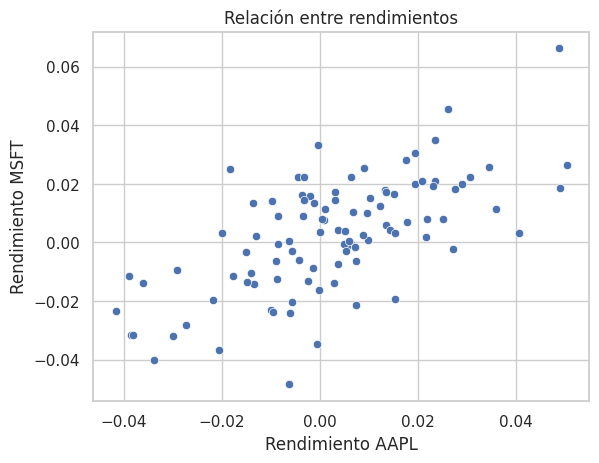

In [11]:
np.random.seed(10)

aapl = np.random.normal(0.001, 0.02, 100)
msft = aapl * 0.6 + np.random.normal(0, 0.015, 100)

sns.scatterplot(x=aapl, y=msft)

plt.title("Relación entre rendimientos")
plt.xlabel("Rendimiento AAPL")
plt.ylabel("Rendimiento MSFT")

plt.show()



## Interpretación

Buscamos patrones:

- nube ascendente → posible relación positiva;
- nube descendente → posible relación negativa;
- nube sin orientación clara → relación lineal débil o inexistente.

Pero recuerda:

> **Correlación no significa causalidad.**

Dos variables pueden moverse juntas sin que una sea la causa de la otra.



# 10. Correlación y mapa de calor

La correlación permite cuantificar la relación lineal entre dos variables.

En Python:

```python
df.corr()
```

produce una matriz de correlaciones.

Valores cercanos a:

- `1` → relación lineal positiva fuerte;
- `0` → relación lineal débil;
- `-1` → relación lineal negativa fuerte.

Veámoslo visualmente.


In [12]:
datos_rendimientos = pd.DataFrame({
    "AAPL": aapl,
    "MSFT": msft,
    "NVDA": aapl * 0.3 + np.random.normal(0, 0.025, 100)
})

correlacion = datos_rendimientos.corr()

correlacion


,AAPL,MSFT,NVDA
AAPL,1.000000,0.648544,0.207646
MSFT,0.648544,1.000000,0.205384
NVDA,0.207646,0.205384,1.000000


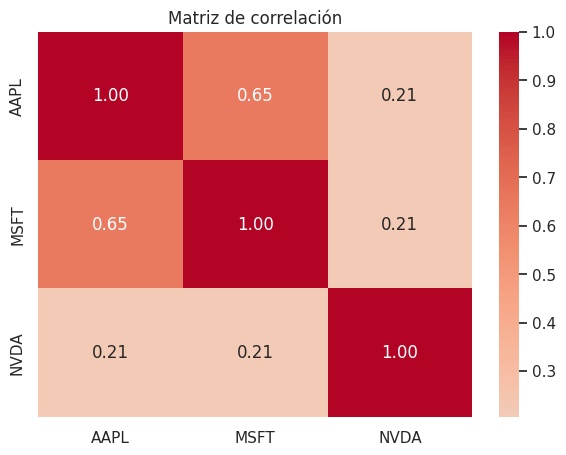

In [13]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación")

plt.show()



## 🧠 Interpretar el heatmap

La matriz permite responder rápidamente:

> ¿Qué activos tienen comportamientos más similares?

Pero debemos tener cuidado:

- la correlación mide principalmente **relación lineal**;
- una correlación histórica no garantiza que se mantenga igual;
- correlación no significa causalidad;
- el período elegido afecta el resultado.

Para un análisis financiero serio también debemos considerar el período, frecuencia, calidad de datos y contexto del mercado.



# 11. Ahora sí: datos reales con yfinance 💰

Hasta este momento utilizamos datos pequeños o simulados para entender la visualización.

Ahora vamos a trabajar con datos reales.

Instalación, si el entorno todavía no tiene la librería:

```bash
pip install yfinance
```

Importamos:


In [14]:
import yfinance as yf



## ¿Qué activos vamos a estudiar?

Usaremos como ejemplo:

- `AAPL` — Apple
- `MSFT` — Microsoft
- `GOOGL` — Alphabet
- `AMZN` — Amazon
- `NVDA` — NVIDIA

Los símbolos son **tickers**, identificadores utilizados para localizar activos en los mercados.

> Los datos obtenidos mediante servicios externos pueden cambiar con el tiempo. Para una clase de EDA esto es útil: cada estudiante puede obtener una fotografía diferente del período consultado.


In [15]:
activos = ["AAPL", "MSFT", "GOOGL", "AMZN", "NVDA"]

precios = yf.download(
    activos,
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=True
)

precios.head()


[*********************100%***********************]  5 of 5 completed


Price            Close                                                 \
Ticker            AAPL        AMZN       GOOGL        MSFT       NVDA   
Date                                                                    
2024-01-02  183.404022  149.929993  136.867599  363.117889  48.028793   
2024-01-03  182.030746  148.470001  137.610535  362.853546  47.431526   
2024-01-04  179.718933  144.570007  135.104401  360.249176  47.859291   
2024-01-05  178.997711  145.240005  134.450607  360.063202  48.955105   
2024-01-08  183.324966  149.100006  137.531296  366.858093  52.101986   

Price             High                                                 ...  \
Ticker            AAPL        AMZN       GOOGL        MSFT       NVDA  ...   
Date                                                                   ...   
2024-01-02  186.170300  152.380005  138.135533  368.042749  49.152535  ...   
2024-01-03  183.641118  151.050003  138.313849  365.457949  48.044747  ...   
2024-01-04  180.884713  147.380005  137.848295  365.301323  48.359839  ...   
2024-01-05  180.558682  146.589996  135.867136  364.283111  49.403805  ...   
2024-01-08  183.364493  149.399994  137.699692  367.357443  52.123926  ...   

Price             Open                                                 \
Ticker            AAPL        AMZN       GOOGL        MSFT       NVDA   
Date                                                                    
2024-01-02  184.895829  151.539993  137.244022  366.045381  49.101684   
2024-01-03  182.001109  149.199997  135.956278  361.296785  47.347769   
2024-01-04  179.956033  145.589996  137.115265  362.922123  47.628956   
2024-01-05  179.797968  144.690002  135.460997  361.257702  48.321942   
2024-01-08  179.896761  146.740005  135.005329  361.580743  49.368910   

Price         Volume                                           
Ticker          AAPL      AMZN     GOOGL      MSFT       NVDA  
Date                                                           
2024-01-02  82488700  47339400  23711200  25258600  411254000  
2024-01-03  58414500  49425500  24212100  23083500  320896000  
2024-01-04  71983600  56039800  27137700  20901500  306535000  
2024-01-05  62379700  45153100  22513900  21004600  415039000  
2024-01-08  59144500  46757100  21404000  23134000  642510000  

[5 rows x 25 columns]


# 12. Antes de graficar: conozcamos nuestros datos

Una regla fundamental de EDA:

> **No empieces a graficar sin conocer primero el DataFrame.**

Preguntas básicas:

- ¿cuántas filas tenemos?
- ¿cuántas columnas?
- ¿qué tipo de datos?
- ¿hay valores faltantes?
- ¿qué período cubren?


In [16]:
print("Dimensiones:", precios.shape)

precios.info()


Dimensiones: (502, 25)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 502 entries, 2024-01-02 to 2025-12-31
Data columns (total 25 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (Close, AAPL)    502 non-null    float64
 1   (Close, AMZN)    502 non-null    float64
 2   (Close, GOOGL)   502 non-null    float64
 3   (Close, MSFT)    502 non-null    float64
 4   (Close, NVDA)    502 non-null    float64
 5   (High, AAPL)     502 non-null    float64
 6   (High, AMZN)     502 non-null    float64
 7   (High, GOOGL)    502 non-null    float64
 8   (High, MSFT)     502 non-null    float64
 9   (High, NVDA)     502 non-null    float64
 10  (Low, AAPL)      502 non-null    float64
 11  (Low, AMZN)      502 non-null    float64
 12  (Low, GOOGL)     502 non-null    float64
 13  (Low, MSFT)      502 non-null    float64
 14  (Low, NVDA)      502 non-null    float64
 15  (Open, AAPL)     502 non-null    float64
 16  (Open, AMZN)     502

In [17]:
precios.describe()


Price        Close                                                  \
Ticker        AAPL        AMZN       GOOGL        MSFT        NVDA   
count   502.000000  502.000000  502.000000  502.000000  502.000000   
mean    218.163909  201.084920  186.196407  436.391724  130.434591   
std      29.061803   23.894482   44.695116   44.590889   36.478682   
min     163.220612  144.570007  130.161423  350.446106   47.431526   
25%     197.301445  182.045002  160.382668  404.577217  107.877956   
50%     220.355461  199.269997  171.818123  420.492233  129.622086   
75%     234.987217  223.067505  193.867214  475.532745  157.790543   
max     285.413116  254.000000  322.601013  537.646362  206.545151   

Price         High                                                  ...  \
Ticker        AAPL        AMZN       GOOGL        MSFT        NVDA  ...   
count   502.000000  502.000000  502.000000  502.000000  502.000000  ...   
mean    220.247259  203.257610  188.240375  439.904432  132.605680  ...   
std      29.157374   24.065589   45.248697   44.664830   36.763190  ...   
min     164.605508  146.589996  131.984099  360.251011   48.044747  ...   
25%     199.331448  184.752499  162.219164  407.837374  110.606060  ...   
50%     222.591319  200.525002  173.761174  423.625032  132.120711  ...   
75%     237.294617  225.872498  195.231444  480.116550  158.770635  ...   
max     287.836498  258.600006  327.977016  550.012986  211.682851  ...   

Price         Open                                                  \
Ticker        AAPL        AMZN       GOOGL        MSFT        NVDA   
count   502.000000  502.000000  502.000000  502.000000  502.000000   
mean    217.941191  201.160956  186.098553  436.394023  130.481371   
std      29.027179   24.115082   44.736023   44.931145   36.636462   
min     163.566886  144.690002  130.636917  346.808771   47.347769   
25%     196.633060  182.320004  160.184682  404.190597  107.114859   
50%     219.779613  199.305000  172.185854  420.292313  129.651093   
75%     234.190526  223.520004  192.999171  476.422488  157.940159   
max     285.423085  255.360001  325.363817  549.795108  207.582673   

Price         Volume                                                          
Ticker          AAPL          AMZN         GOOGL          MSFT          NVDA  
count   5.020000e+02  5.020000e+02  5.020000e+02  5.020000e+02  5.020000e+02  
mean    5.564712e+07  4.270025e+07  3.183945e+07  2.138683e+07  2.992817e+08  
std     2.732569e+07  1.823593e+07  1.448971e+07  8.027734e+06  1.537611e+08  
min     1.791060e+07  1.142050e+07  1.009740e+07  5.855900e+06  6.552850e+07  
25%     4.132715e+07  3.153310e+07  2.236578e+07  1.632950e+07  1.841153e+08  
50%     4.890840e+07  3.871275e+07  2.853320e+07  1.958820e+07  2.505988e+08  
75%     6.041002e+07  4.680382e+07  3.582398e+07  2.359505e+07  3.779842e+08  
max     3.186799e+08  1.663408e+08  1.274901e+08  7.083610e+07  1.142269e+09  

[8 rows x 25 columns]

In [20]:
precios.tail()

Price            Close                                                  \
Ticker            AAPL        AMZN       GOOGL        MSFT        NVDA   
Date                                                                     
2025-12-24  273.066711  232.380005  313.480194  484.943420  188.169678   
2025-12-26  272.657837  232.520004  312.901337  484.635406  190.085205   
2025-12-29  273.016876  232.070007  312.951233  484.029236  187.780594   
2025-12-30  272.338684  232.529999  313.240662  484.406860  187.102188   
2025-12-31  271.122009  230.820007  312.392334  480.571167  186.064606   

Price             High                                                  ...  \
Ticker            AAPL        AMZN       GOOGL        MSFT        NVDA  ...   
Date                                                                    ...   
2025-12-24  274.682309  232.949997  314.468262  486.076248  188.468980  ...   
2025-12-26  274.622490  232.990005  314.478256  485.042825  192.240166  ...   
2025-12-29  273.615223  232.600006  313.410331  485.271356  188.319327  ...   
2025-12-30  273.335969  232.770004  316.334649  486.592973  188.548815  ...   
2025-12-31  272.937076  232.990005  313.969253  485.062692  190.115125  ...   

Price             Open                                                  \
Ticker            AAPL        AMZN       GOOGL        MSFT        NVDA   
Date                                                                     
2025-12-24  271.600701  232.130005  314.158867  482.618176  187.501244   
2025-12-26  273.415784  232.039993  313.869455  483.641711  189.476629   
2025-12-29  271.949773  231.940002  310.765482  481.803337  187.271790   
2025-12-30  272.069428  231.210007  311.893277  482.866614  187.800566   
2025-12-31  272.318764  232.910004  312.242631  484.764565  189.127446   

Price         Volume                                           
Ticker          AAPL      AMZN     GOOGL      MSFT       NVDA  
Date                                                           
2025-12-24  17910600  11420500  10097400   5855900   65528500  
2025-12-26  21521800  15994700  10899000   8842200  139740300  
2025-12-29  23715200  19797900  19621800  10893400  120006100  
2025-12-30  22139600  21910500  17380900  13944500   97687300  
2025-12-31  27293600  24383700  16377700  15601600  120100500  

[5 rows x 25 columns]

In [18]:
precios.isna().sum()


Price   Ticker
Close   AAPL      0
        AMZN      0
        GOOGL     0
        MSFT      0
        NVDA      0
High    AAPL      0
        AMZN      0
        GOOGL     0
        MSFT      0
        NVDA      0
Low     AAPL      0
        AMZN      0
        GOOGL     0
        MSFT      0
        NVDA      0
Open    AAPL      0
        AMZN      0
        GOOGL     0
        MSFT      0
        NVDA      0
Volume  AAPL      0
        AMZN      0
        GOOGL     0
        MSFT      0
        NVDA      0
dtype: int64


### 🧪 Mini-reto

Antes de continuar, responde:

1. ¿Cuántas observaciones tenemos?
2. ¿Cuál es la primera fecha?
3. ¿Cuál es la última fecha?
4. ¿Existen valores faltantes?
5. ¿Qué representa cada nivel de columnas?

**No continúes hasta intentar responderlas.**


# Respuesta Mini- reto

1. Dimensiones: (filas 502, columnas 25)
2. 2024-01-02
3. 2025-12-31 Ejecute el codigo precios.tail() para hallar la respuesta.
4. No
5. Niveles de columnas: el primer nivel identifica el tipo de precio o dato bursátil; el segundo identifica la empresa mediante su ticker.



# 13. Seleccionar el precio de cierre

`yfinance` devuelve varias variables para cada activo, entre ellas:

- Open
- High
- Low
- Close
- Volume

Para nuestro primer análisis utilizaremos **Close**, el precio de cierre ajustado según la configuración utilizada.



In [21]:
cierre = precios["Close"]

cierre.head()


Ticker,AAPL,AMZN,GOOGL,MSFT,NVDA
Date,,,,,
2024-01-02,183.404022,149.929993,136.867599,363.117889,48.028793
2024-01-03,182.030746,148.470001,137.610535,362.853546,47.431526
2024-01-04,179.718933,144.570007,135.104401,360.249176,47.859291
2024-01-05,178.997711,145.240005,134.450607,360.063202,48.955105
2024-01-08,183.324966,149.100006,137.531296,366.858093,52.101986



## Visualicemos los precios

Primera pregunta del EDA:

> **¿Cómo evolucionaron los precios de los activos durante el período?**


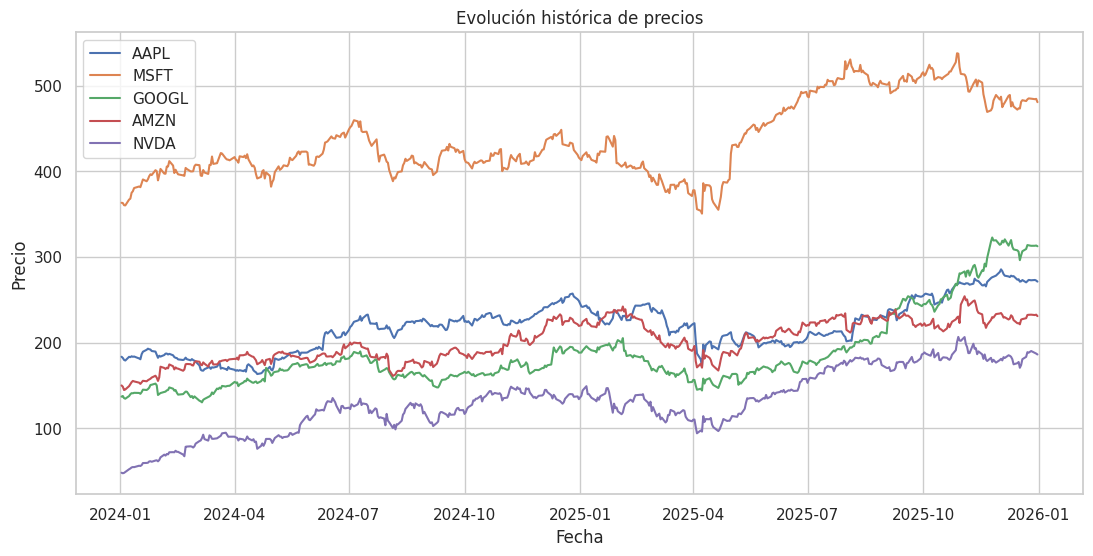

In [22]:
fig, ax = plt.subplots(figsize=(13, 6))

for activo in activos:
    ax.plot(cierre.index, cierre[activo], label=activo)

ax.set_title("Evolución histórica de precios")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio")
ax.legend()

plt.show()



## ⚠️ Una dificultad de comparar precios

AAPL puede tener un precio nominal diferente de NVDA, MSFT, etc.

Eso hace que comparar las alturas directamente pueda ser engañoso.

Una solución sencilla para estudiar **crecimiento relativo** es normalizar las series.

Por ejemplo:

```python
precio_normalizado = precio / precio_inicial * 100
```

Así todos comienzan en 100.


In [23]:
cierre_normalizado = cierre / cierre.iloc[0] * 100

cierre_normalizado.head()


Ticker,AAPL,AMZN,GOOGL,MSFT,NVDA
Date,,,,,
2024-01-02,100.000000,100.000000,100.000000,100.000000,100.000000
2024-01-03,99.251229,99.026218,100.542813,99.927202,98.756439
2024-01-04,97.990726,96.425008,98.711749,99.209977,99.647082
2024-01-05,97.597484,96.871882,98.234065,99.158761,101.928659
2024-01-08,99.956895,99.446417,100.484918,101.030025,108.480731


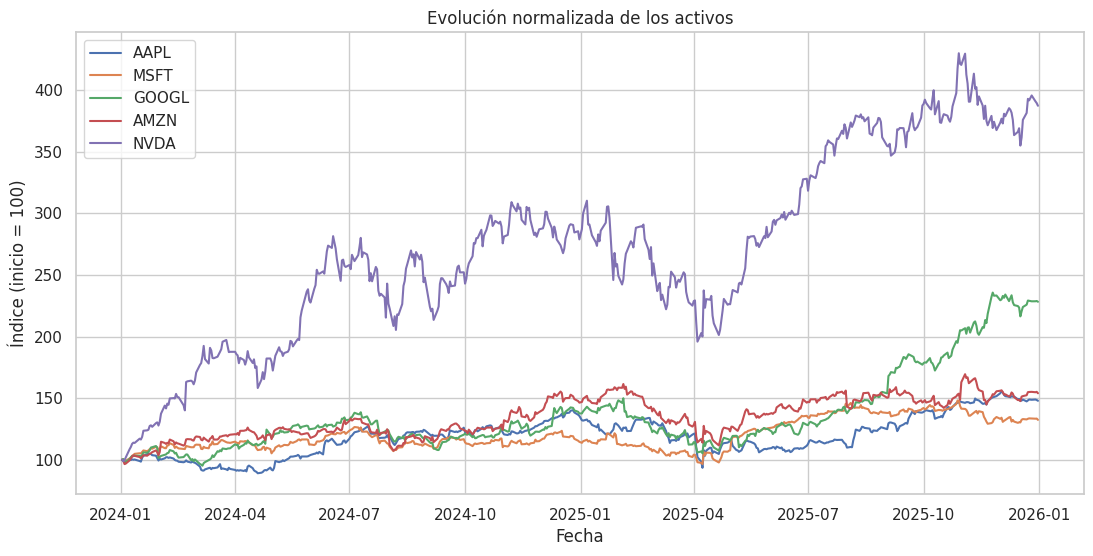

In [24]:
fig, ax = plt.subplots(figsize=(13, 6))

for activo in activos:
    ax.plot(
        cierre_normalizado.index,
        cierre_normalizado[activo],
        label=activo
    )

ax.set_title("Evolución normalizada de los activos")
ax.set_xlabel("Fecha")
ax.set_ylabel("Índice (inicio = 100)")
ax.legend()

plt.show()



### ¿Qué pregunta responde este gráfico?

No responde:

> "¿Cuál tiene el precio más alto?"

Responde mejor:

> **"¿Cómo cambió cada activo respecto a su propio punto inicial?"**

Esta distinción es fundamental en análisis de datos financieros.



# 14. Rendimientos: transformar los precios

En análisis financiero suele ser útil estudiar **rendimientos** en lugar de precios.

Un rendimiento porcentual simple entre dos períodos puede calcularse como:

\[
R_t = \frac{P_t-P_{t-1}}{P_{t-1}}
\]

En Pandas podemos obtenerlo con:

```python
pct_change()
```


In [25]:
rendimientos = cierre.pct_change()

rendimientos.head()


Ticker,AAPL,AMZN,GOOGL,MSFT,NVDA
Date,,,,,
2024-01-02,NaN,NaN,NaN,NaN,NaN
2024-01-03,-0.007488,-0.009738,0.005428,-0.000728,-0.012436
2024-01-04,-0.012700,-0.026268,-0.018212,-0.007177,0.009019
2024-01-05,-0.004013,0.004634,-0.004839,-0.000516,0.022897
2024-01-08,0.024175,0.026577,0.022913,0.018871,0.064281



El primer registro normalmente será `NaN` porque no tenemos un precio anterior con el cual compararlo.

Eliminemos esos valores para las visualizaciones que lo necesiten.


In [26]:
rendimientos = rendimientos.dropna()

rendimientos.head()


Ticker,AAPL,AMZN,GOOGL,MSFT,NVDA
Date,,,,,
2024-01-03,-0.007488,-0.009738,0.005428,-0.000728,-0.012436
2024-01-04,-0.012700,-0.026268,-0.018212,-0.007177,0.009019
2024-01-05,-0.004013,0.004634,-0.004839,-0.000516,0.022897
2024-01-08,0.024175,0.026577,0.022913,0.018871,0.064281
2024-01-09,-0.002263,0.015225,0.015197,0.002936,0.016975



# 15. EDA de los rendimientos

### Pregunta 1
**¿Cómo se comportan los rendimientos a través del tiempo?**


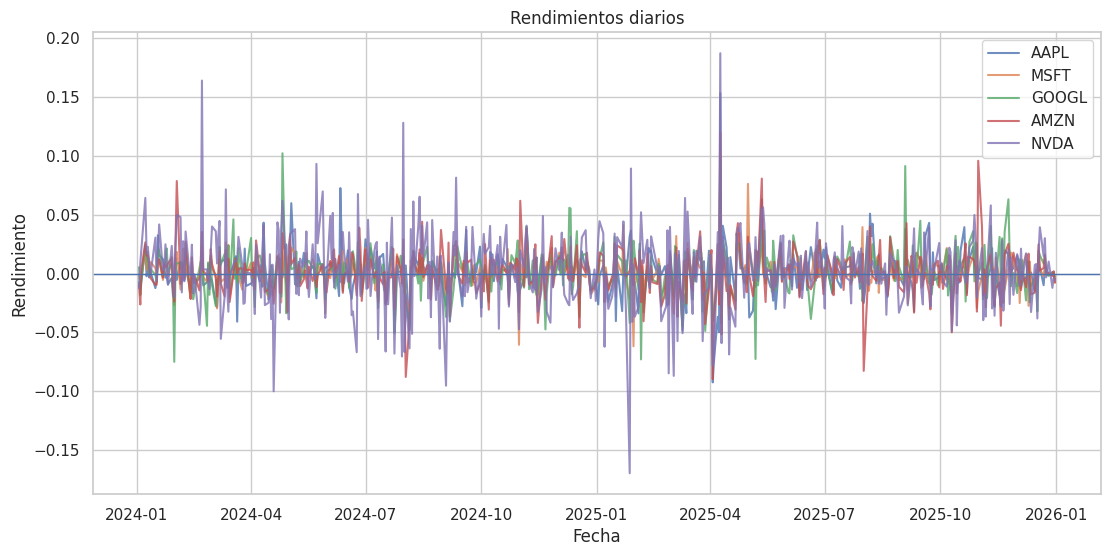

In [27]:
fig, ax = plt.subplots(figsize=(13, 6))

for activo in activos:
    ax.plot(
        rendimientos.index,
        rendimientos[activo],
        label=activo,
        alpha=0.8
    )

ax.axhline(0, linewidth=1)
ax.set_title("Rendimientos diarios")
ax.set_xlabel("Fecha")
ax.set_ylabel("Rendimiento")
ax.legend()

plt.show()



### Interpretación

La línea horizontal en cero nos ayuda a distinguir:

- valores positivos → rendimiento positivo;
- valores negativos → rendimiento negativo.

Busca:

- períodos de mayor variabilidad;
- movimientos extremos;
- momentos donde varios activos caen simultáneamente;
- diferencias entre activos.

**No confundas variabilidad con rendimiento.**

Un activo puede tener grandes movimientos hacia arriba y hacia abajo y terminar cerca del punto inicial.



# 16. Distribución de rendimientos

Ahora usamos Seaborn para estudiar una variable desde otro ángulo.

Pregunta:

> **¿Cómo se distribuyen los rendimientos diarios de cada activo?**


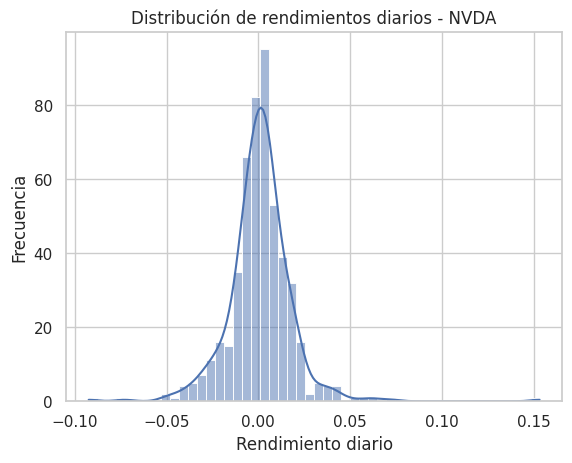

In [33]:
sns.histplot(
    data=rendimientos,
    x="AAPL",
    bins=50,
    kde=True
)

plt.title("Distribución de rendimientos diarios - NVDA")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")

plt.show()


## 🧪 Cambia el activo

Modifica `"AAPL"` por:

```python
"MSFT"
"GOOGL"
"AMZN"
"NVDA"
```

### Pregunta

¿Qué diferencias observas entre las distribuciones?

No busques solamente cuál "se ve mejor".

Describe:

- centro;
- dispersión;
- valores extremos;
- forma de la distribución.


# Respuesta:

las cuatro empresas tienen la mayoría de sus rendimientos diarios cerca de cero, pero no todas presentan la misma variación.
NVIDIA muestra los cambios más grandes, mientras que Microsoft tiene los resultados más concentrados. Google y Amazon presentan un comportamiento intermedio, con algunos días en los que sus precios también cambian considerablemente.

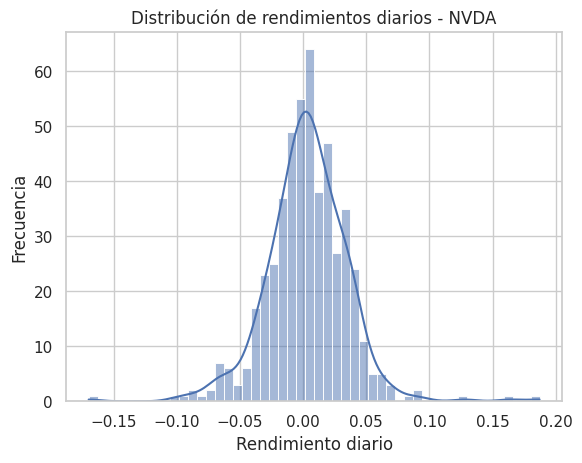

In [36]:
sns.histplot(
    data=rendimientos,
    x="NVDA",
    bins=50,
    kde=True
)

plt.title("Distribución de rendimientos diarios - NVDA")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")

plt.show()

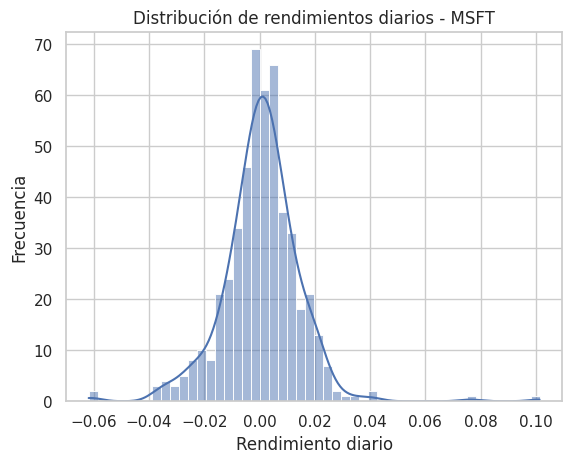

In [38]:
sns.histplot(
    data=rendimientos,
    x="MSFT",
    bins=50,
    kde=True
)

plt.title("Distribución de rendimientos diarios - MSFT")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")

plt.show()

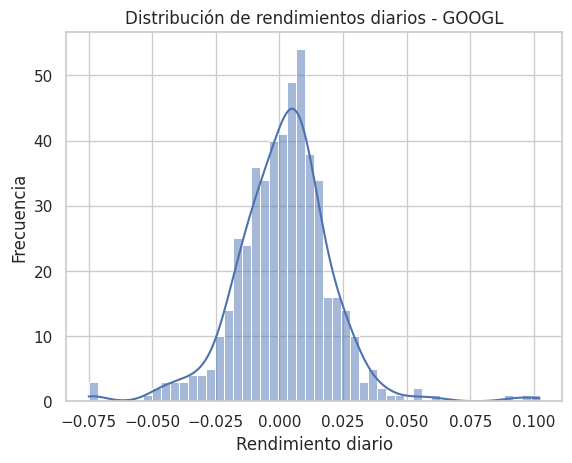

In [39]:
sns.histplot(
    data=rendimientos,
    x="GOOGL",
    bins=50,
    kde=True
)

plt.title("Distribución de rendimientos diarios - GOOGL")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")

plt.show()

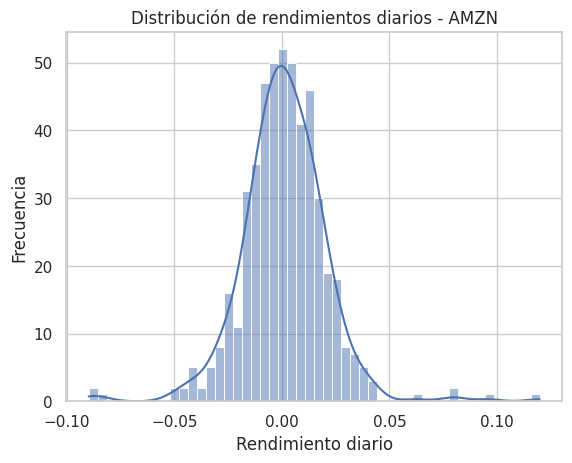

In [40]:
sns.histplot(
    data=rendimientos,
    x="AMZN",
    bins=50,
    kde=True
)

plt.title("Distribución de rendimientos diarios - AMZN")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")

plt.show()


# 17. Comparar la dispersión con un boxplot

Ahora podemos comparar todos los activos simultáneamente.


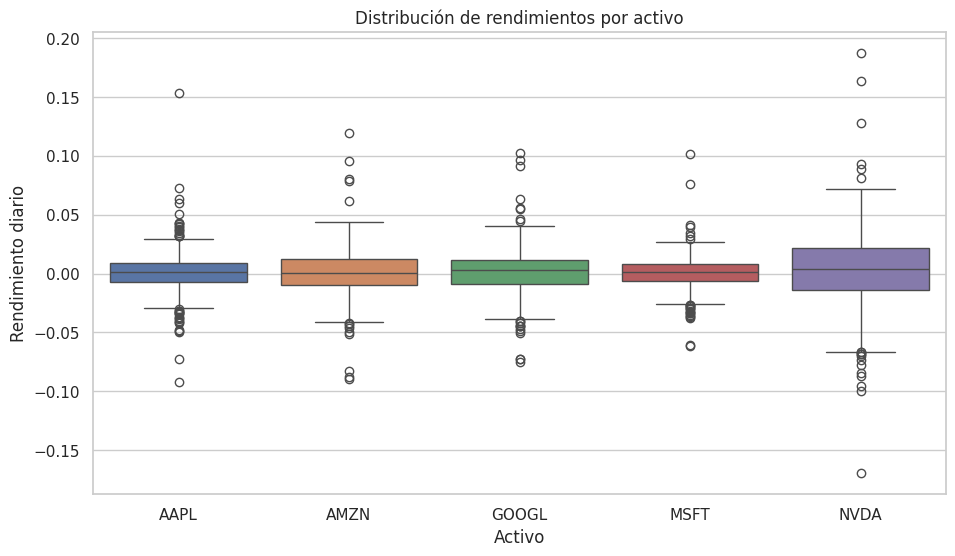

In [41]:
plt.figure(figsize=(11, 6))

sns.boxplot(data=rendimientos)

plt.title("Distribución de rendimientos por activo")
plt.xlabel("Activo")
plt.ylabel("Rendimiento diario")

plt.show()



### Preguntas de análisis

1. ¿Qué activos muestran mayor dispersión?
2. ¿Qué activos presentan más observaciones alejadas?
3. ¿Las medianas están cerca de cero?
4. ¿Qué información perderíamos si solo observáramos el precio?

Aquí aparece una idea importante:

> **Una buena visualización permite comparar una propiedad concreta de los datos.**


# RESPUESTA

1. NVDA es la que presenta mayores cambios en sus rendimientos. Le siguen AMZN, GOOGL, AAPL y MSFT, que muestran cambios más pequeños.

2. NVDA y AAPL presentan varios valores alejados de los demás, lo que significa que tuvieron días con cambios muy grandes en sus precios.

3. Sí, las medianas de los cinco activos están cerca de cero, lo que indica que sus cambios diarios suelen ser pequeños.

4. No podríamos ver claramente cuánto varía el precio cada día ni identificar qué acciones presentan cambios más fuertes y, por lo tanto, mayor riesgo.


# 18. Matriz de correlación del portafolio

Ahora llegamos a una de las visualizaciones más importantes para nuestro caso.

Pregunta:

> **¿Cómo se relacionan los rendimientos de los activos entre sí?**


In [ ]:
correlacion = rendimientos.corr()

correlacion


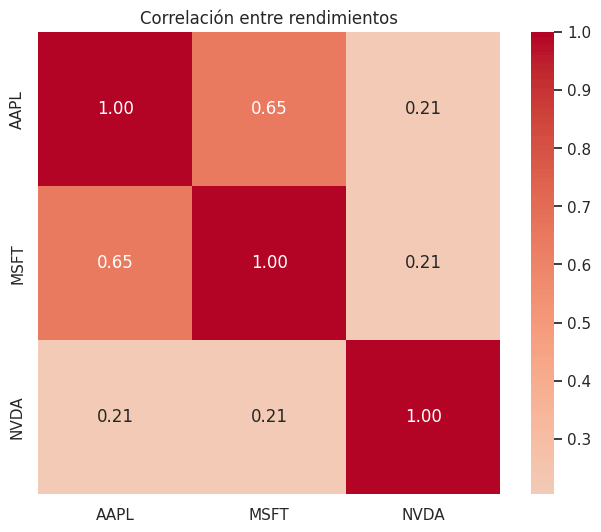

In [42]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlación entre rendimientos")

plt.show()



## 🧠 ¿Cómo leer la matriz?

Supongamos que encontramos:

```text
             AAPL    MSFT
AAPL          1.00   0.70
MSFT          0.70   1.00
```

La diagonal es 1 porque cada activo está perfectamente correlacionado consigo mismo.

Un valor de `0.70` indica una relación lineal positiva relativamente alta en el período analizado.

### Pregunta de portafolio

Si dos activos presentan una correlación elevada:

> ¿Qué implica esto para la diversificación?

Una posible interpretación es que **pueden proporcionar menos diversificación entre sí que dos activos con una correlación menor**, aunque la diversificación real depende de muchos otros factores.

No debemos convertir la correlación, por sí sola, en una recomendación de inversión.



# 19. Scatter plot: profundicemos en una pareja

Seleccionemos dos activos:

```python
AAPL
MSFT
```

Cada punto representa un día.

- X → rendimiento de AAPL
- Y → rendimiento de MSFT



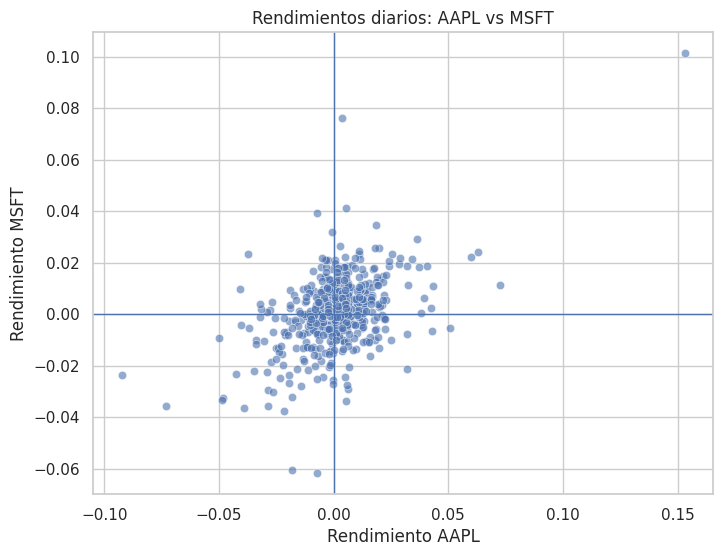

In [43]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=rendimientos,
    x="AAPL",
    y="MSFT",
    alpha=0.6
)

plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)

plt.title("Rendimientos diarios: AAPL vs MSFT")
plt.xlabel("Rendimiento AAPL")
plt.ylabel("Rendimiento MSFT")

plt.show()



### Preguntas para interpretar

Observa la nube de puntos:

1. ¿Existe una orientación ascendente?
2. ¿Qué ocurre cuando AAPL tiene rendimiento negativo?
3. ¿MSFT suele tener el mismo signo?
4. ¿Hay valores extremos?
5. ¿La relación parece perfectamente lineal?

El scatter plot y la matriz de correlación están contando historias relacionadas, pero desde perspectivas diferentes:

**Scatter → vemos las observaciones individuales.**  
**Correlación → resumimos numéricamente la relación lineal.**


# Respuestas

1. Sí, cuando AAPL sube, MSFT también suele subir.

2. Cuando AAPL baja, MSFT también suele bajar o tener cambios pequeños.

3. Sí, generalmente ambas acciones suben o bajan al mismo tiempo, aunque hay algunas excepciones.

4. Sí, hay algunos días en los que una o ambas acciones presentan cambios mucho más grandes de lo normal.

5. No, porque los puntos no forman una línea recta exacta, aunque sí muestran una tendencia similar entre ambas acciones.



# 20. Estadísticas descriptivas del portafolio

La visualización debe complementarse con medidas numéricas.



In [44]:
resumen = pd.DataFrame({
    "Media": rendimientos.mean(),
    "Mediana": rendimientos.median(),
    "Desviación estándar": rendimientos.std(),
    "Mínimo": rendimientos.min(),
    "Máximo": rendimientos.max()
})

resumen


,Media,Mediana,Desviación estándar,Mínimo,Máximo
Ticker,,,,,
AAPL,0.000933,0.001187,0.017571,-0.092456,0.153289
AMZN,0.001056,0.000648,0.019781,-0.089791,0.119770
GOOGL,0.001829,0.002923,0.019062,-0.075003,0.102243
MSFT,0.000657,0.001111,0.013975,-0.061809,0.101337
NVDA,0.003222,0.003504,0.032181,-0.169682,0.187227



## ¿Qué estamos viendo?

### Media
Promedio de los rendimientos.

### Mediana
Valor central de la distribución.

### Desviación estándar
Medida de dispersión utilizada frecuentemente como una aproximación de la volatilidad histórica.

### Mínimo / máximo
Permiten observar los extremos registrados en el período.

**Importante:** estas estadísticas describen el período analizado. No garantizan que el futuro se comporte igual.



# 21. Mini-proyecto: EDA completo

Ahora debes construir tu propio análisis.

## Objetivo

Selecciona entre **3 y 5 activos** y realiza un EDA.

### Paso 1 — Datos

Descarga los datos históricos.

### Paso 2 — Calidad

Revisa:

- dimensiones;
- tipos;
- valores faltantes;
- período.

### Paso 3 — Precios

Construye un gráfico de evolución de precios.

### Paso 4 — Normalización

Construye un gráfico con todas las series comenzando en 100.

### Paso 5 — Rendimientos

Calcula los rendimientos diarios.

### Paso 6 — Distribución

Construye un histograma para uno de los activos.

### Paso 7 — Comparación

Construye un boxplot de los rendimientos.

### Paso 8 — Relación

Construye una matriz de correlación.

### Paso 9 — Relación entre dos activos

Construye un scatter plot.

### Paso 10 — Conclusiones

Escribe **3 hallazgos**.

Cada hallazgo debe tener esta estructura:

> **Gráfico:** ¿qué gráfico utilizaste?  
> **Observación:** ¿qué ves?  
> **Interpretación:** ¿qué significa esa observación para el análisis?


In [45]:
import yfinance as yf

activos = ["TSLA", "JPM", "KO"]

precios = yf.download(
    activos,
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=True
)

precios.head()

[*********************100%***********************]  3 of 3 completed


Price            Close                               High             \
Ticker             JPM         KO        TSLA         JPM         KO   
Date                                                                   
2024-01-02  161.472687  55.309334  248.419998  161.557136  55.364811   
2024-01-03  160.768936  55.438774  238.449997  161.435163  55.660679   
2024-01-04  161.835846  55.253864  237.929993  163.667489  55.716162   
2024-01-05  162.647781  55.170643  237.490005  163.695782  55.429532   
2024-01-08  162.411774  55.577473  240.449997  162.732779  55.642194   

Price                          Low                               Open  \
Ticker            TSLA         JPM         KO        TSLA         JPM   
Date                                                                    
2024-01-02  251.250000  158.498093  54.246047  244.410004  158.666990   
2024-01-03  245.679993  159.868106  55.253854  236.320007  161.266265   
2024-01-04  242.699997  161.014430  55.161406  237.729996  161.108850   
2024-01-05  240.119995  161.892463  54.634379  234.899994  161.892463   
2024-01-08  241.250000  160.023089  54.939499  235.300003  162.411774   

Price                                Volume                       
Ticker             KO        TSLA       JPM        KO       TSLA  
Date                                                              
2024-01-02  54.366245  250.080002   9977400  16322600  104654200  
2024-01-03  55.411037  244.979996   9852300  14830600  121082600  
2024-01-04  55.521998  239.250000  11972500  12912900  102629300  
2024-01-05  55.290841  236.860001  10066000  10412800   92488900  
2024-01-08  55.179896  236.139999  11229900  11554600   85166600

In [46]:
print("Dimensiones:", precios.shape)
precios.info()

Dimensiones: (502, 15)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 502 entries, 2024-01-02 to 2025-12-31
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, JPM)    502 non-null    float64
 1   (Close, KO)     502 non-null    float64
 2   (Close, TSLA)   502 non-null    float64
 3   (High, JPM)     502 non-null    float64
 4   (High, KO)      502 non-null    float64
 5   (High, TSLA)    502 non-null    float64
 6   (Low, JPM)      502 non-null    float64
 7   (Low, KO)       502 non-null    float64
 8   (Low, TSLA)     502 non-null    float64
 9   (Open, JPM)     502 non-null    float64
 10  (Open, KO)      502 non-null    float64
 11  (Open, TSLA)    502 non-null    float64
 12  (Volume, JPM)   502 non-null    int64  
 13  (Volume, KO)    502 non-null    int64  
 14  (Volume, TSLA)  502 non-null    int64  
dtypes: float64(12), int64(3)
memory usage: 62.8 KB


In [47]:
precios.isna().sum()


Price   Ticker
Close   JPM       0
        KO        0
        TSLA      0
High    JPM       0
        KO        0
        TSLA      0
Low     JPM       0
        KO        0
        TSLA      0
Open    JPM       0
        KO        0
        TSLA      0
Volume  JPM       0
        KO        0
        TSLA      0
dtype: int64

In [48]:

precios.head()

Price            Close                               High             \
Ticker             JPM         KO        TSLA         JPM         KO   
Date                                                                   
2024-01-02  161.472687  55.309334  248.419998  161.557136  55.364811   
2024-01-03  160.768936  55.438774  238.449997  161.435163  55.660679   
2024-01-04  161.835846  55.253864  237.929993  163.667489  55.716162   
2024-01-05  162.647781  55.170643  237.490005  163.695782  55.429532   
2024-01-08  162.411774  55.577473  240.449997  162.732779  55.642194   

Price                          Low                               Open  \
Ticker            TSLA         JPM         KO        TSLA         JPM   
Date                                                                    
2024-01-02  251.250000  158.498093  54.246047  244.410004  158.666990   
2024-01-03  245.679993  159.868106  55.253854  236.320007  161.266265   
2024-01-04  242.699997  161.014430  55.161406  237.729996  161.108850   
2024-01-05  240.119995  161.892463  54.634379  234.899994  161.892463   
2024-01-08  241.250000  160.023089  54.939499  235.300003  162.411774   

Price                                Volume                       
Ticker             KO        TSLA       JPM        KO       TSLA  
Date                                                              
2024-01-02  54.366245  250.080002   9977400  16322600  104654200  
2024-01-03  55.411037  244.979996   9852300  14830600  121082600  
2024-01-04  55.521998  239.250000  11972500  12912900  102629300  
2024-01-05  55.290841  236.860001  10066000  10412800   92488900  
2024-01-08  55.179896  236.139999  11229900  11554600   85166600

In [49]:
precios.tail()


Price            Close                               High             \
Ticker             JPM         KO        TSLA         JPM         KO   
Date                                                                   
2025-12-24  322.950104  68.774155  485.399994  323.754587  68.823205   
2025-12-26  321.713867  68.538734  475.190002  324.608106  68.823210   
2025-12-29  317.632477  68.823212  459.640015  321.576505  69.078252   
2025-12-30  317.308746  68.734924  454.429993  318.800014  68.901683   
2025-12-31  316.131409  68.577965  449.720001  318.741150  68.823201   

Price                          Low                               Open  \
Ticker            TSLA         JPM         KO        TSLA         JPM   
Date                                                                    
2025-12-24  490.899994  319.349438  68.421013  476.799988  320.075446   
2025-12-26  489.089996  320.369759  68.401403  473.820007  322.891174   
2025-12-29  469.399994  317.416633  68.519113  459.000000  320.821065   
2025-12-30  463.119995  316.396297  68.470072  453.829987  318.672466   
2025-12-31  456.549988  315.954817  68.548530  449.299988  318.211345   

Price                               Volume                     
Ticker             KO        TSLA      JPM       KO      TSLA  
Date                                                           
2025-12-24  68.568157  488.480011  4289300  4515300  41285400  
2025-12-26  68.617204  485.230011  4158300  5711400  58780700  
2025-12-29  68.666257  469.000000  8635300  9686900  66263000  
2025-12-30  68.666258  461.089996  7904300  8610900  59238500  
2025-12-31  68.734912  456.100006  5048500  8127800  49078000

# Calidad de los datos:

Se obtuvieron 502 registros y 15 columnas, correspondientes a los activos seleccionados. No se encontraron valores faltantes. Los datos abarcan desde el 2 de enero de 2024 hasta el 31 de diciembre de 2025, por lo que se cuenta con información de dos años para realizar el análisis.

In [50]:
precios.columns

MultiIndex([( 'Close',  'JPM'),
            ( 'Close',   'KO'),
            ( 'Close', 'TSLA'),
            (  'High',  'JPM'),
            (  'High',   'KO'),
            (  'High', 'TSLA'),
            (   'Low',  'JPM'),
            (   'Low',   'KO'),
            (   'Low', 'TSLA'),
            (  'Open',  'JPM'),
            (  'Open',   'KO'),
            (  'Open', 'TSLA'),
            ('Volume',  'JPM'),
            ('Volume',   'KO'),
            ('Volume', 'TSLA')],
           names=['Price', 'Ticker'])

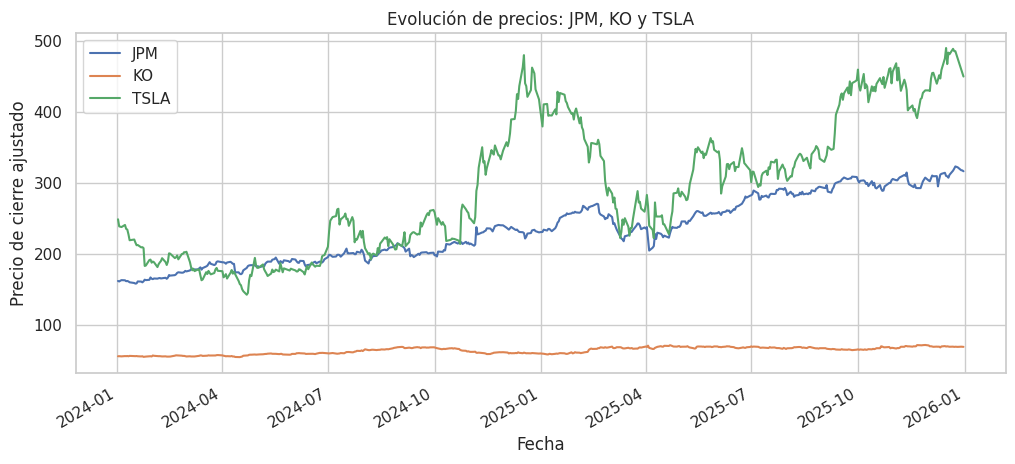

In [51]:
import matplotlib.pyplot as plt

precios["Close"].plot(figsize=(12, 5))

plt.title("Evolución de precios: JPM, KO y TSLA")
plt.xlabel("Fecha")
plt.ylabel("Precio de cierre ajustado")
plt.legend()
plt.grid(True)

plt.show()

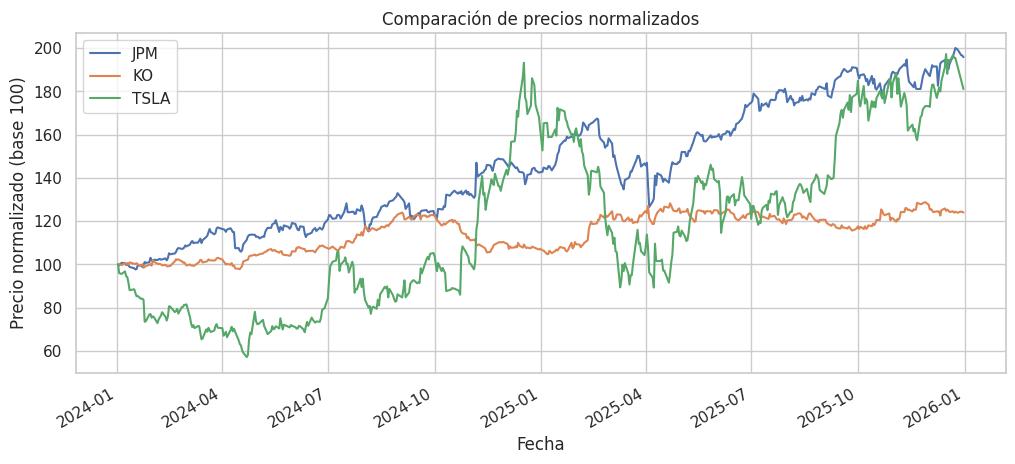

In [52]:
precios_norm = precios["Close"] / precios["Close"].iloc[0] * 100

precios_norm.plot(figsize=(12, 5))

plt.title("Comparación de precios normalizados")
plt.xlabel("Fecha")
plt.ylabel("Precio normalizado (base 100)")
plt.legend()
plt.grid(True)

plt.show()

In [53]:

rendimientos = precios["Close"].pct_change()

rendimientos.head()

Ticker,JPM,KO,TSLA
Date,,,
2024-01-02,NaN,NaN,NaN
2024-01-03,-0.004358,0.002340,-0.040134
2024-01-04,0.006636,-0.003335,-0.002181
2024-01-05,0.005017,-0.001506,-0.001849
2024-01-08,-0.001451,0.007374,0.012464


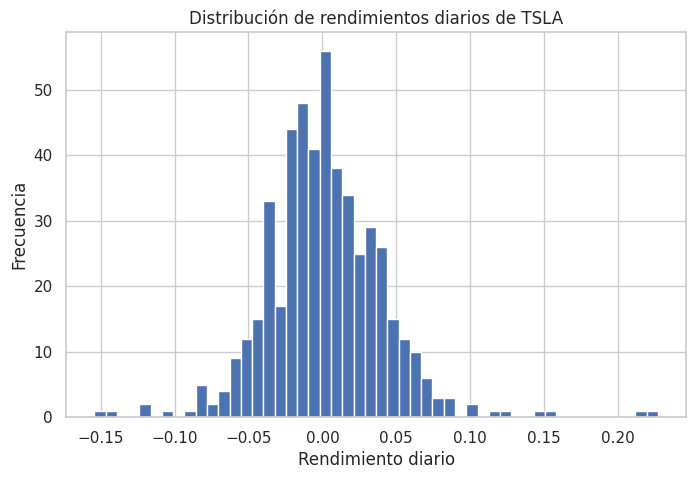

In [54]:
rendimientos["TSLA"].hist(bins=50, figsize=(8, 5))

plt.title("Distribución de rendimientos diarios de TSLA")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")
plt.grid(True)

plt.show()

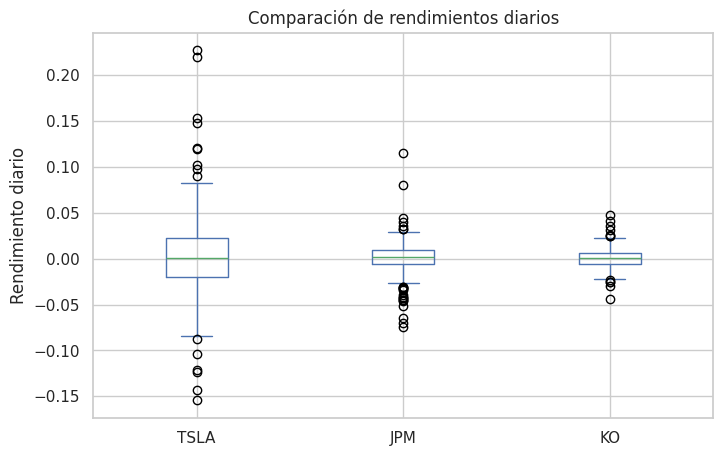

In [55]:
rendimientos[["TSLA", "JPM", "KO"]].plot(
    kind="box",
    figsize=(8, 5)
)

plt.title("Comparación de rendimientos diarios")
plt.ylabel("Rendimiento diario")
plt.grid(True)

plt.show()

In [56]:
correlacion = rendimientos.corr()

correlacion

Ticker,JPM,KO,TSLA
Ticker,,,
JPM,1.000000,0.065967,0.368614
KO,0.065967,1.000000,-0.093175
TSLA,0.368614,-0.093175,1.000000


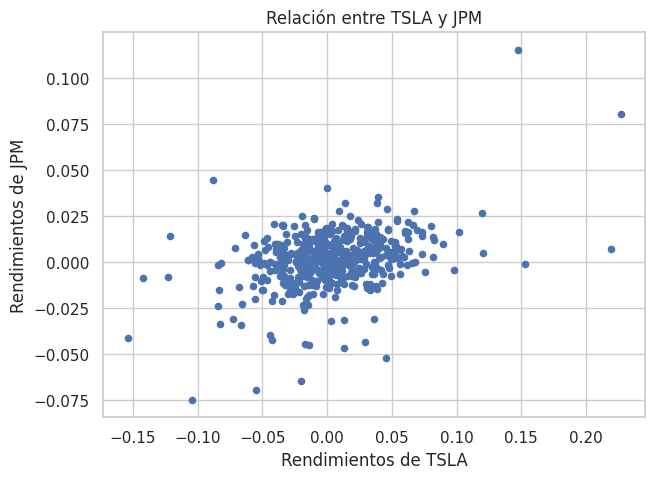

In [57]:
rendimientos.plot(
    kind="scatter",
    x="TSLA",
    y="JPM",
    figsize=(7, 5)
)

plt.title("Relación entre TSLA y JPM")
plt.xlabel("Rendimientos de TSLA")
plt.ylabel("Rendimientos de JPM")
plt.grid(True)

plt.show()

# CONCLUSIONES

Análisis de los gráficos de TSLA, JPM y KO

Hallazgo 1

Gráfico: Comparación de precios normalizados.

Observación: TSLA y JPM muestran un crecimiento importante durante el período analizado, mientras que KO presenta un crecimiento más moderado.

Interpretación: Esto indica que TSLA y JPM aumentaron más su valor durante el período estudiado, mientras que KO tuvo un comportamiento más estable.

Hallazgo 2

Gráfico: Comparación de rendimientos diarios.

Observación: TSLA presenta cambios más grandes en sus rendimientos diarios que JPM y KO. En cambio, los cambios de JPM y KO son más pequeños.

Interpretación: Esto significa que el precio de TSLA tiene mayores subidas y bajadas de un día a otro, mientras que JPM y KO presentan cambios diarios menos pronunciados.

Hallazgo 3

Gráfico: Relación entre TSLA y JPM.

Observación: Los puntos del gráfico están dispersos y no forman una línea diagonal claramente definida.

Interpretación: Esto sugiere que los cambios diarios de TSLA y JPM no siempre ocurren de la misma manera. Cuando uno sube o baja, no necesariamente el otro presenta un cambio similar.


# 22. Reto final 🎯

Sin modificar el código inicialmente:

### Pregunta 1
¿Cuál activo presenta mayor dispersión de rendimientos?

### Pregunta 2
¿Cuáles dos activos presentan mayor correlación?

### Pregunta 3
¿Cuáles presentan menor correlación?

### Pregunta 4
¿Existe algún día donde varios activos tengan movimientos extremos simultáneamente?

### Pregunta 5
¿La evolución normalizada cuenta la misma historia que los precios originales?

### Pregunta 6
¿Qué información aporta el histograma que no aporta el gráfico temporal?

### Pregunta 7
¿Qué información aporta el scatter plot que no aporta el heatmap?

---

## ⭐ Regla de oro del EDA

Antes de hacer un gráfico pregunta:

> **¿Qué quiero saber?**

Después del gráfico pregunta:

> **¿Qué estoy observando?**

Y finalmente:

> **¿Qué puedo concluir razonablemente a partir de lo observado?**


Reto final 🎯

1. TSLA presenta la mayor dispersión, porque sus rendimientos diarios muestran cambios más grandes que los de JPM y KO.

2. Los activos que presentan mayor correlación son TSLA y JPM, con un valor de 0,368614.

3. Los activos que presentan menor correlación son KO y TSLA, con un valor de -0,093175.

4. En los gráficos se observa que TSLA presenta algunos cambios diarios muy grandes, mientras que JPM y KO muestran variaciones más moderadas. No se puede asegurar únicamente con estos gráficos que los tres activos hayan tenido movimientos extremos el mismo día. Para confirmarlo, sería necesario revisar los rendimientos diarios de cada activo y comparar las fechas.

5. Sí, ambos gráficos muestran la evolución de los precios, pero el gráfico normalizado permite comparar mejor los cambios de los tres activos porque todos parten de una misma base de 100.

6. El histograma permite ver cuáles cambios diarios fueron más frecuentes y si hubo rendimientos muy altos o muy bajos. El gráfico temporal, en cambio, permite observar cómo fueron cambiando los precios a lo largo del tiempo.

7. El gráfico de dispersión permite observar cómo se relacionan los rendimientos de dos activos día a día y si sus movimientos siguen algún patrón. El mapa de calor resume esa relación con un número, lo que facilita comparar la correlación entre todos los activos.



# 📚 Referencias

- [Matplotlib — documentación oficial](https://matplotlib.org/stable/)
- [Matplotlib — galería de ejemplos](https://matplotlib.org/stable/gallery/)
- [Matplotlib — introducción a Figure y Axes](https://matplotlib.org/stable/users/explain/figure/figure_intro.html)
- [Seaborn — documentación oficial](https://seaborn.pydata.org/)
- [Pandas — visualización](https://pandas.pydata.org/docs/user_guide/visualization.html)
- [yfinance — documentación](https://ranaroussi.github.io/yfinance/)

### Nota sobre los datos

Los datos obtenidos mediante `yfinance` corresponden a información histórica de mercado y pueden cambiar dependiendo del período consultado, ajustes y disponibilidad. Este notebook tiene finalidad educativa y de análisis de datos; no constituye asesoría financiera.
